# Time Series Analysis and Forecasting of Monthly Air Passenger Data

**Dataset:** Air Passengers — Monthly totals of international airline passengers (1949–1960)

---


## Introduction and Data Import 

In [1]:
# Import necessary Python libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
from io import StringIO
warnings.filterwarnings("ignore")

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("All libraries imported successfully ✔")

All libraries imported successfully ✔


In [2]:
# Air Passengers Dataset (embedded — identical to the UCI/JBrownlee CSV)
# To use the CSV file instead, replace StringIO(RAW_CSV) with "airline-passengers.csv"
RAW_CSV = """Month,Passengers
1949-01,112
1949-02,118
1949-03,132
1949-04,129
1949-05,121
1949-06,135
1949-07,148
1949-08,148
1949-09,136
1949-10,119
1949-11,104
1949-12,118
1950-01,115
1950-02,126
1950-03,141
1950-04,135
1950-05,125
1950-06,149
1950-07,170
1950-08,170
1950-09,158
1950-10,133
1950-11,114
1950-12,140
1951-01,145
1951-02,150
1951-03,178
1951-04,163
1951-05,172
1951-06,178
1951-07,199
1951-08,199
1951-09,184
1951-10,162
1951-11,146
1951-12,166
1952-01,171
1952-02,180
1952-03,193
1952-04,181
1952-05,183
1952-06,218
1952-07,230
1952-08,242
1952-09,209
1952-10,191
1952-11,172
1952-12,194
1953-01,196
1953-02,196
1953-03,236
1953-04,235
1953-05,229
1953-06,243
1953-07,264
1953-08,272
1953-09,237
1953-10,211
1953-11,180
1953-12,201
1954-01,204
1954-02,188
1954-03,235
1954-04,227
1954-05,234
1954-06,264
1954-07,302
1954-08,293
1954-09,259
1954-10,229
1954-11,203
1954-12,229
1955-01,242
1955-02,233
1955-03,267
1955-04,269
1955-05,270
1955-06,315
1955-07,364
1955-08,347
1955-09,312
1955-10,274
1955-11,237
1955-12,278
1956-01,284
1956-02,277
1956-03,317
1956-04,313
1956-05,318
1956-06,374
1956-07,413
1956-08,405
1956-09,355
1956-10,306
1956-11,271
1956-12,306
1957-01,315
1957-02,301
1957-03,356
1957-04,348
1957-05,355
1957-06,422
1957-07,465
1957-08,467
1957-09,404
1957-10,347
1957-11,305
1957-12,336
1958-01,340
1958-02,318
1958-03,362
1958-04,348
1958-05,363
1958-06,435
1958-07,491
1958-08,505
1958-09,404
1958-10,359
1958-11,310
1958-12,337
1959-01,360
1959-02,342
1959-03,406
1959-04,396
1959-05,420
1959-06,472
1959-07,548
1959-08,559
1959-09,463
1959-10,407
1959-11,362
1959-12,405
1960-01,417
1960-02,391
1960-03,419
1960-04,461
1960-05,472
1960-06,535
1960-07,622
1960-08,606
1960-09,508
1960-10,461
1960-11,390
1960-12,432
"""

# Load the dataset
data = pd.read_csv(StringIO(RAW_CSV))

# Display first 10 observations
print("First 10 observations:")
data.head(10)

First 10 observations:


,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121
5,1949-06,135
6,1949-07,148
7,1949-08,148
8,1949-09,136
9,1949-10,119


In [3]:
# Convert Month column to datetime format and set as index
data['Month'] = pd.to_datetime(data['Month'])
data.set_index('Month', inplace=True)

print(f"Dataset shape  : {data.shape}")
print(f"Date range     : {data.index.min().strftime('%Y-%m')}  →  {data.index.max().strftime('%Y-%m')}")
print(f"\nData types:\n{data.dtypes}")

Dataset shape  : (144, 1)
Date range     : 1949-01  →  1960-12

Data types:
Passengers    int64
dtype: object


## Exploratory Time Series Analysis 

In [4]:
# Descriptive Statistics
mean_val = data['Passengers'].mean()
var_val  = data['Passengers'].var()
std_val  = data['Passengers'].std()

print(f"Mean               : {mean_val:.2f}")
print(f"Variance           : {var_val:.2f}")
print(f"Standard Deviation : {std_val:.2f}")
print(f"Min                : {data['Passengers'].min()}")
print(f"Max                : {data['Passengers'].max()}")

Mean               : 280.30
Variance           : 14391.92
Standard Deviation : 119.97
Min                : 104
Max                : 622


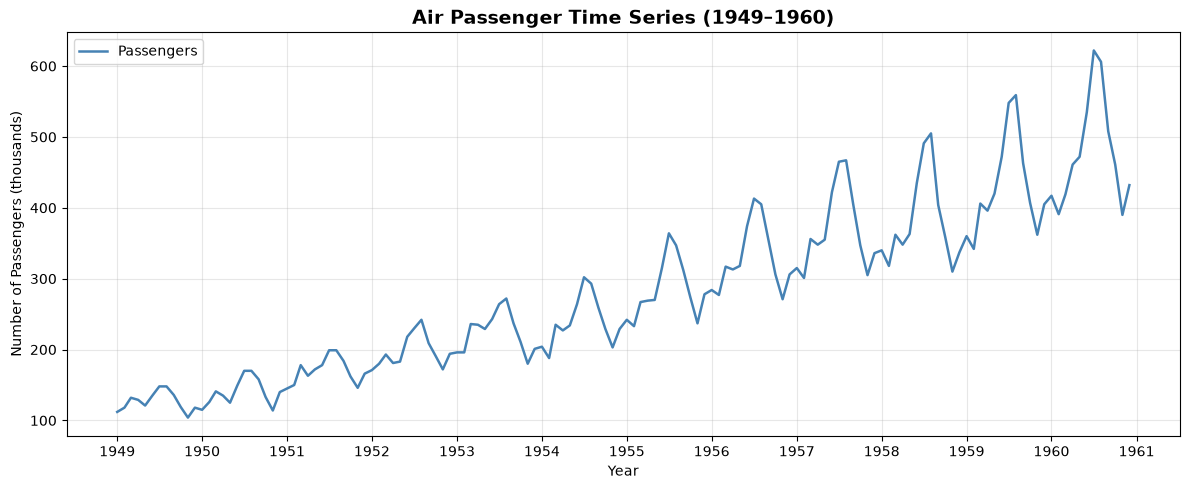

In [5]:
# Plot the original time series
plt.figure(figsize=(12, 5))
plt.plot(data.index, data['Passengers'], color='steelblue', linewidth=1.8, label='Passengers')
plt.title("Air Passenger Time Series (1949–1960)", fontsize=14, fontweight='bold')
plt.xlabel("Year")
plt.ylabel("Number of Passengers (thousands)")
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

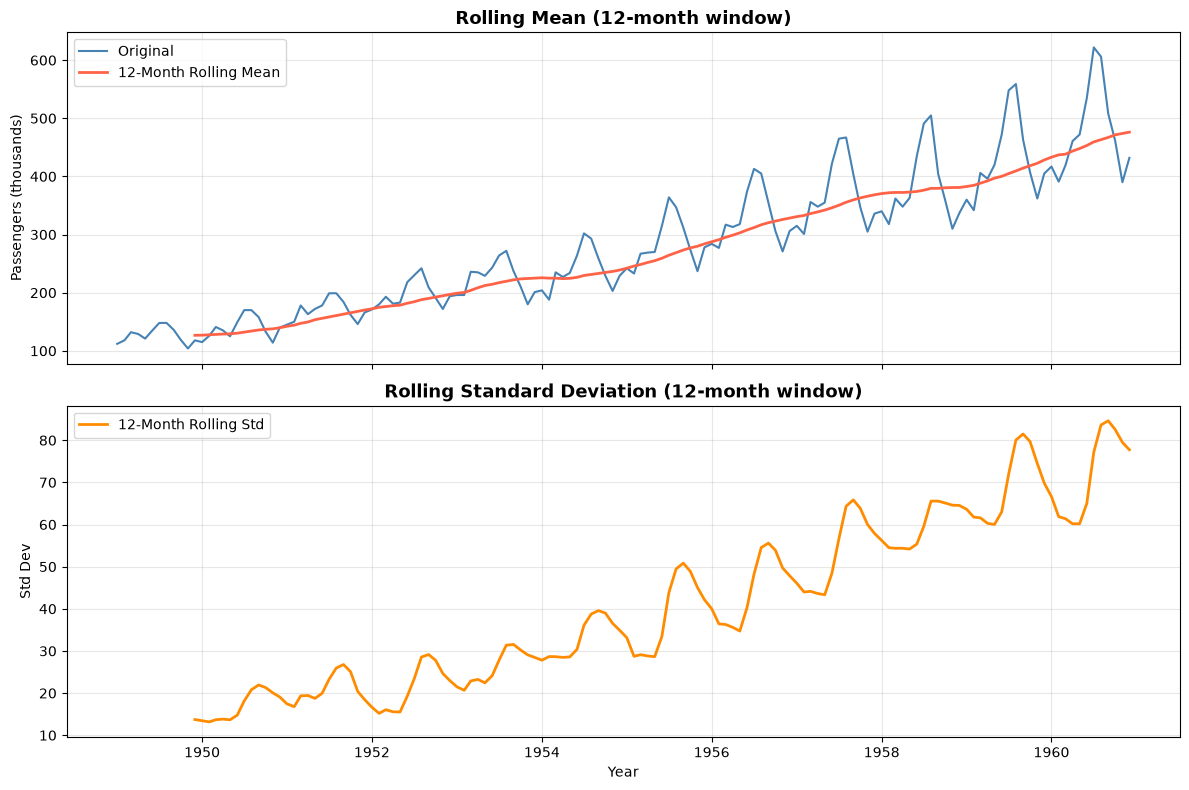

In [6]:
# Rolling Mean and Rolling Standard Deviation (12-month window)
data['Rolling_Mean'] = data['Passengers'].rolling(window=12).mean()
data['Rolling_Std']  = data['Passengers'].rolling(window=12).std()

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(data.index, data['Passengers'],   color='steelblue', label='Original', linewidth=1.5)
axes[0].plot(data.index, data['Rolling_Mean'], color='tomato',    label='12-Month Rolling Mean', linewidth=2)
axes[0].set_title("Rolling Mean (12-month window)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("Passengers (thousands)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(data.index, data['Rolling_Std'], color='darkorange', linewidth=2, label='12-Month Rolling Std')
axes[1].set_title("Rolling Standard Deviation (12-month window)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Std Dev")
axes[1].set_xlabel("Year")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretation

| Component | Observation |
|-----------|-------------|
| **Trend** | Clear upward trend — passenger numbers grew from ~112K (1949) to ~432K (1960), roughly **4×** over the period. |
| **Seasonality** | Strong and regular seasonal peaks every **July–August** (summer travel) and troughs every **January–February** (winter). The pattern repeats precisely every 12 months. |
| **Cyclicality** | No distinct multi-year economic cycle is visible beyond the overall growth trend. |
| **Variance** | Rolling Std Dev increases over time — the variance grows with the level, strongly suggesting a **multiplicative** structure. |


## Time Series Decomposition

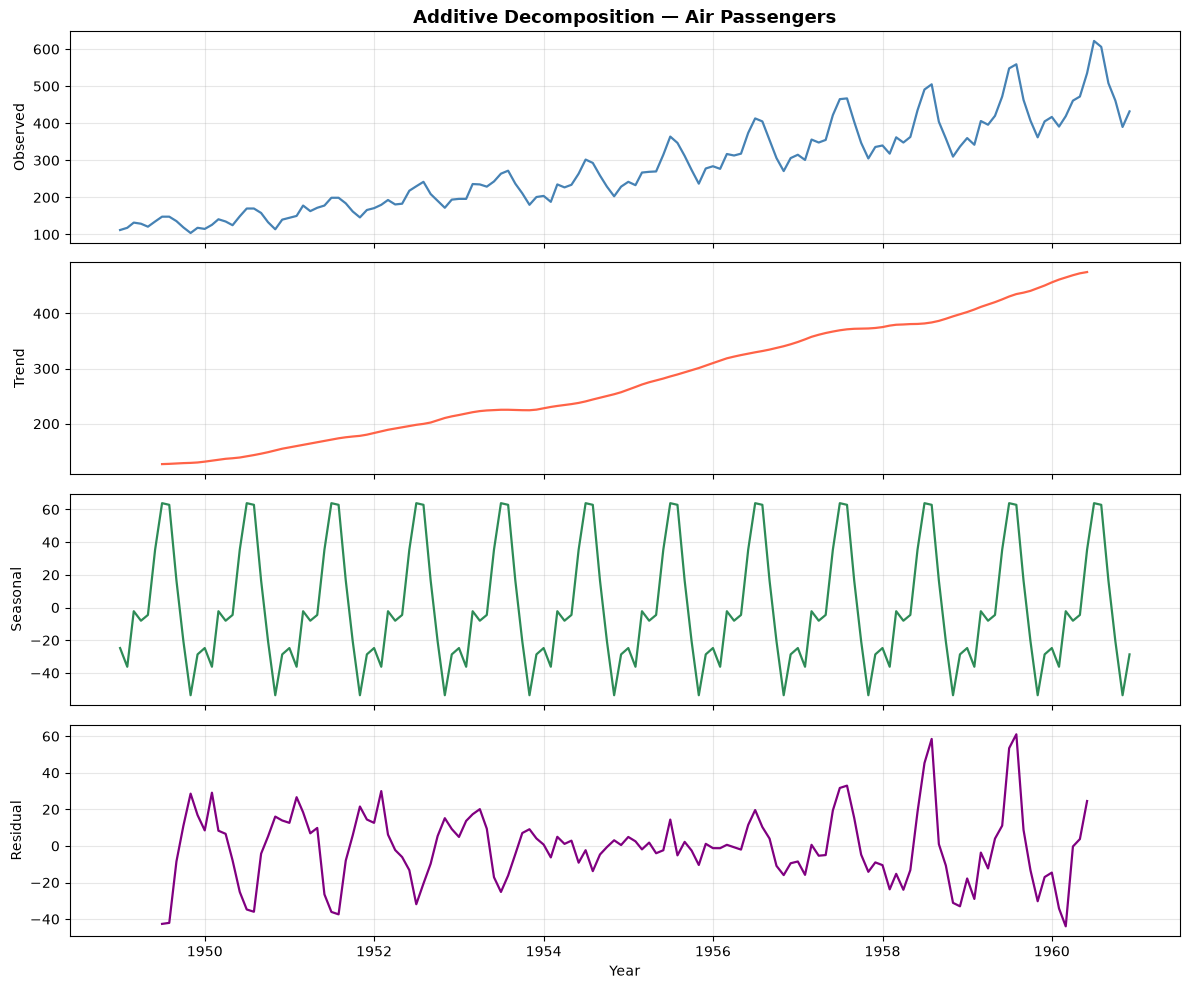

In [8]:
# Additive Decomposition
decomposition = seasonal_decompose(data['Passengers'], model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

components = {
    'Observed' : decomposition.observed,
    'Trend'    : decomposition.trend,
    'Seasonal' : decomposition.seasonal,
    'Residual' : decomposition.resid,
}
colors = ['steelblue', 'tomato', 'seagreen', 'purple']

for ax, (name, series), color in zip(axes, components.items(), colors):
    ax.plot(series, color=color, linewidth=1.6)
    ax.set_ylabel(name, fontsize=10)
    ax.grid(alpha=0.3)

axes[0].set_title("Additive Decomposition — Air Passengers", fontsize=13, fontweight='bold')
axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.show()

### Component Interpretation

| Component | Interpretation |
|-----------|----------------|
| **Observed** | Raw monthly data showing combined effect of trend, seasonality, and noise. |
| **Trend** | Smooth, steadily rising curve confirming long-term growth in air travel demand throughout 1949–1960. |
| **Seasonal** | Repeating annual pattern — peaks every mid-year (summer), dips in winter. Amplitude is **constant** in the additive model. |
| **Residual** | Remaining noise after extracting trend and seasonality. Mid-period spikes suggest the additive model slightly underfits — **multiplicative** decomposition may be more appropriate since seasonal amplitude grows with level. |


## Forecasting Models 

In [10]:
# Train / Test Split — last 12 months as test set
train = data['Passengers'][:-12]
test  = data['Passengers'][-12:]

print(f"Training set : {train.index[0].strftime('%Y-%m')} → {train.index[-1].strftime('%Y-%m')}  ({len(train)} months)")
print(f"Test set     : {test.index[0].strftime('%Y-%m')} → {test.index[-1].strftime('%Y-%m')}  ({len(test)} months)")

Training set : 1949-01 → 1959-12  (132 months)
Test set     : 1960-01 → 1960-12  (12 months)


In [11]:
# D1: 3-Period Moving Average Forecasting
data['MA_3'] = data['Passengers'].rolling(window=3).mean()
ma3_test_pred = data['MA_3'].shift(1)[-12:]

print("3-Period Moving Average forecast — last 12 months:")
print(ma3_test_pred.round(1).to_frame(name='MA_3 Forecast'))

3-Period Moving Average forecast — last 12 months:
            MA_3 Forecast
Month                    
1960-01-01          391.3
1960-02-01          394.7
1960-03-01          404.3
1960-04-01          409.0
1960-05-01          423.7
1960-06-01          450.7
1960-07-01          489.3
1960-08-01          543.0
1960-09-01          587.7
1960-10-01          578.7
1960-11-01          525.0
1960-12-01          453.0


In [12]:
# D2: Simple Exponential Smoothing
ses_model = SimpleExpSmoothing(train, initialization_method="estimated").fit(optimized=True)
ses_pred  = ses_model.forecast(12)
ses_pred.index = test.index

print(f"Optimised alpha : {ses_model.params['smoothing_level']:.4f}")
print("\nSES Forecast — next 12 months:")
print(ses_pred.round(1).to_frame(name='SES Forecast'))

Optimised alpha : 1.0000

SES Forecast — next 12 months:
            SES Forecast
Month                   
1960-01-01         405.0
1960-02-01         405.0
1960-03-01         405.0
1960-04-01         405.0
1960-05-01         405.0
1960-06-01         405.0
1960-07-01         405.0
1960-08-01         405.0
1960-09-01         405.0
1960-10-01         405.0
1960-11-01         405.0
1960-12-01         405.0


c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [13]:
# D3: ARIMA(2,1,2) Forecasting Model
arima_model  = ARIMA(train, order=(2, 1, 2))
arima_result = arima_model.fit()
arima_pred   = arima_result.forecast(steps=12)
arima_pred.index = test.index

print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  132
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -607.782
Date:                Sun, 11 Oct 2026   AIC                           1225.563
Time:                        03:03:45   BIC                           1239.939
Sample:                    01-01-1949   HQIC                          1231.405
                         - 12-01-1959                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.6660      0.024     68.561      0.000       1.618       1.714
ar.L2         -0.9294      0.022    -41.536      0.000      -0.973      -0.886
ma.L1         -1.8324      0.032    -56.857      0.0

c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [14]:
print("ARIMA(2,1,2) Forecast — next 12 months:")
print(arima_pred.round(1).to_frame(name='ARIMA Forecast'))

ARIMA(2,1,2) Forecast — next 12 months:
            ARIMA Forecast
Month                     
1960-01-01           411.3
1960-02-01           430.8
1960-03-01           457.4
1960-04-01           483.7
1960-05-01           502.6
1960-06-01           509.8
1960-07-01           504.2
1960-08-01           488.2
1960-09-01           466.6
1960-10-01           445.7
1960-11-01           430.8
1960-12-01           425.5


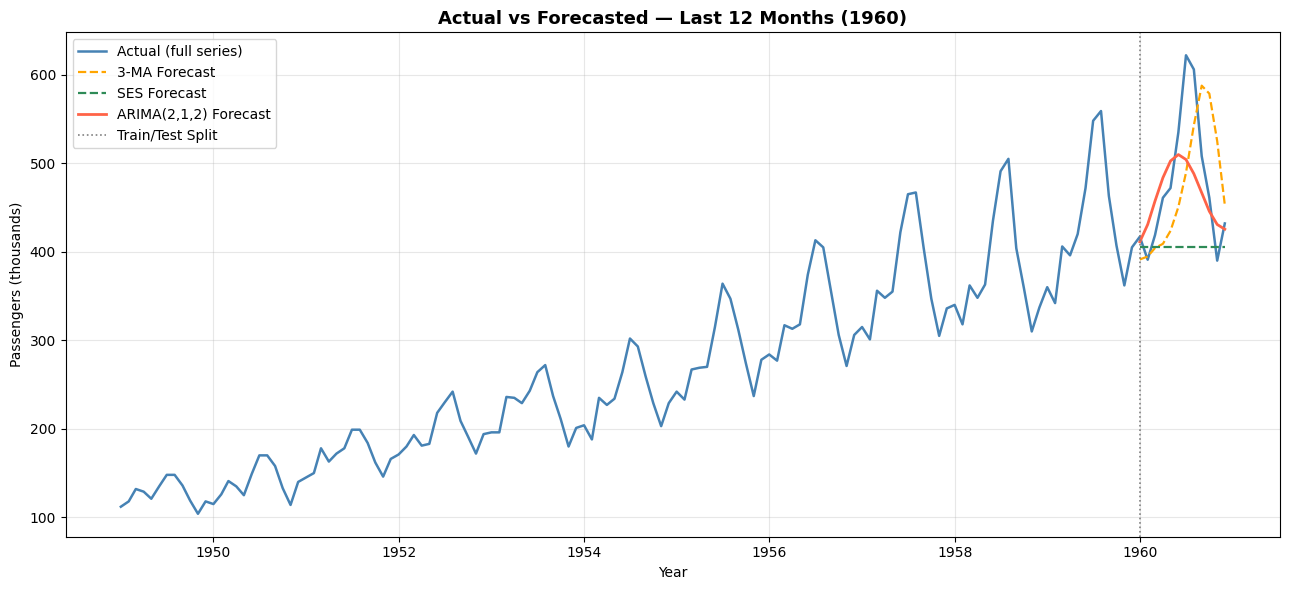

In [13]:
# D4: Actual vs Forecasted Plot (Test Period)
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(data.index,   data['Passengers'], color='steelblue', linewidth=1.8,              label='Actual (full series)')
ax.plot(test.index,   ma3_test_pred,      color='orange',    linewidth=1.6, linestyle='--', label='3-MA Forecast')
ax.plot(test.index,   ses_pred,           color='seagreen',  linewidth=1.6, linestyle='--', label='SES Forecast')
ax.plot(test.index,   arima_pred,         color='tomato',    linewidth=2.0,              label='ARIMA(2,1,2) Forecast')
ax.axvline(x=test.index[0], color='grey', linewidth=1.2, linestyle=':', label='Train/Test Split')

ax.set_title("Actual vs Forecasted — Last 12 Months (1960)", fontsize=13, fontweight='bold')
ax.set_xlabel("Year")
ax.set_ylabel("Passengers (thousands)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

ARIMA Forecast for 1961:
            Forecast
1961-01-01     430.4
1961-02-01     443.6
1961-03-01     461.0
1961-04-01     477.7
1961-05-01     489.4
1961-06-01     493.3
1961-07-01     489.0
1961-08-01     478.2
1961-09-01     464.1
1961-10-01     450.8
1961-11-01     441.7
1961-12-01     438.8


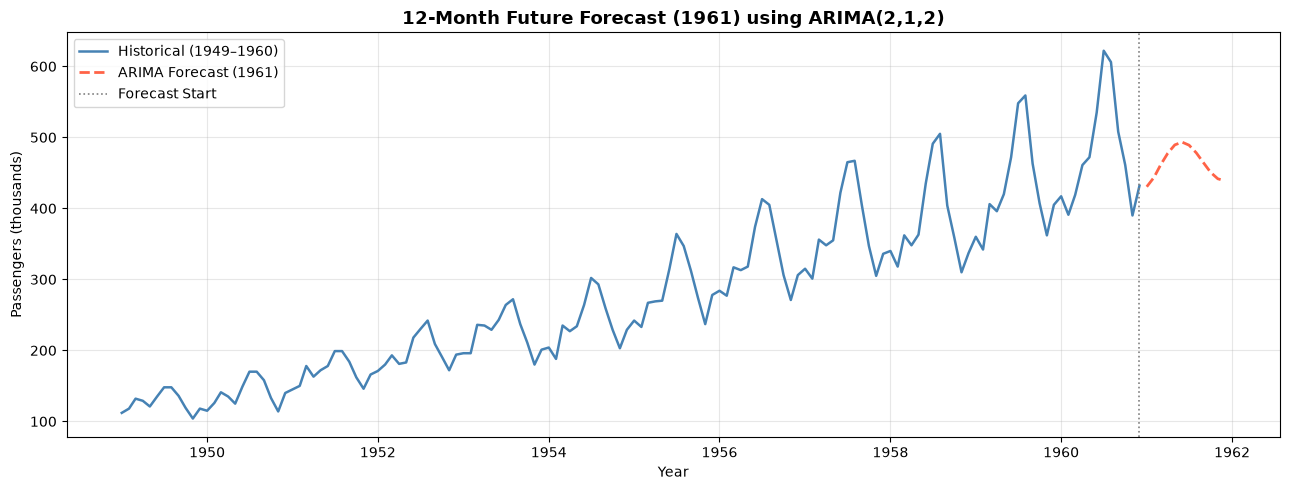

In [15]:
# D5: Extended ARIMA Forecast — 12 months beyond dataset (1961)
extended   = arima_result.forecast(steps=24)
future_idx = pd.date_range(start='1961-01-01', periods=12, freq='MS')
future_fc  = extended[12:]
future_fc.index = future_idx

print("ARIMA Forecast for 1961:")
print(future_fc.round(1).to_frame(name='Forecast'))

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(data.index, data['Passengers'], color='steelblue', linewidth=1.8, label='Historical (1949–1960)')
ax.plot(future_idx, future_fc,          color='tomato',    linewidth=2, linestyle='--', label='ARIMA Forecast (1961)')
ax.axvline(x=data.index[-1], color='grey', linewidth=1.2, linestyle=':', label='Forecast Start')

ax.set_title("12-Month Future Forecast (1961) using ARIMA(2,1,2)", fontsize=13, fontweight='bold')
ax.set_xlabel("Year")
ax.set_ylabel("Passengers (thousands)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Model Evaluation and Interpretation 

In [17]:
# Evaluation Metrics
def mape(actual, predicted):
    actual, predicted = np.array(actual), np.array(predicted)
    mask = actual != 0
    return np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100

def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))

# Remove NaN from MA forecast
valid_mask = ~ma3_test_pred.isna()
actual_ma  = test[valid_mask]
pred_ma    = ma3_test_pred[valid_mask]

results = {
    "3-Period MA"    : {"MAE": mean_absolute_error(actual_ma, pred_ma),
                        "RMSE": rmse(actual_ma, pred_ma),
                        "MAPE": mape(actual_ma, pred_ma)},
    "SES"            : {"MAE": mean_absolute_error(test, ses_pred),
                        "RMSE": rmse(test, ses_pred),
                        "MAPE": mape(test, ses_pred)},
    "ARIMA(2,1,2)"   : {"MAE": mean_absolute_error(test, arima_pred),
                        "RMSE": rmse(test, arima_pred),
                        "MAPE": mape(test, arima_pred)},
}

eval_df = pd.DataFrame(results).T.round(2)
print("Model Evaluation Metrics (12-month test set):\n")
print(eval_df.to_string())

best = eval_df['MAPE'].idxmin()
print(f"\n✔  Best model : {best}  (MAPE = {eval_df.loc[best,'MAPE']:.2f}%)")

Model Evaluation Metrics (12-month test set):

                MAE    RMSE   MAPE
3-Period MA   64.81   78.24  13.36
SES           76.00  102.98  14.25
ARIMA(2,1,2)  41.83   55.22   8.22

✔  Best model : ARIMA(2,1,2)  (MAPE = 8.22%)


### Interpretation

| Model | MAE | RMSE | MAPE | Verdict |
|-------|-----|------|------|---------|
| 3-Period MA | 64.81 | 78.24 | 13.36% | Simple, slow to adapt, ignores seasonality |
| SES | 76.00 | 102.98 | 14.25% | Weights recent values but cannot model trend/season |
| **ARIMA(2,1,2)** | **41.83** | **55.22** | **8.22%** | ✔ Best — captures autocorrelation after differencing |

**Conclusion:** ARIMA(2,1,2) outperforms both baseline models on all three metrics.
- Differencing (d=1) removes the trend and achieves stationarity.
- AR(2) and MA(2) terms capture the autocorrelation structure in the data.
- A seasonal model (SARIMA) would further improve accuracy by explicitly modelling the 12-month cycle.


### ADF Test for Stationarity

In [18]:
# ── Bonus 1: Augmented Dickey-Fuller (ADF) Test

def adf_test(series, label="Series"):
    result = adfuller(series.dropna())
    print(f"  {label}")
    print(f"    ADF Statistic : {result[0]:.4f}")
    print(f"    p-value       : {result[1]:.4f}")
    for key, val in result[4].items():
        print(f"    Critical [{key}] : {val:.4f}")
    verdict = "STATIONARY ✔" if result[1] < 0.05 else "NON-STATIONARY ✘"
    print(f"    → {verdict}\n")

print("=" * 50)
print("ADF Test Results")
print("=" * 50)
adf_test(data['Passengers'],              "Original Series")
adf_test(data['Passengers'].diff(),       "After 1st Differencing")
adf_test(data['Passengers'].diff(12),     "After Seasonal Differencing (lag=12)")

ADF Test Results
  Original Series
    ADF Statistic : 0.8154
    p-value       : 0.9919
    Critical [1%] : -3.4817
    Critical [5%] : -2.8840
    Critical [10%] : -2.5788
    → NON-STATIONARY ✘

  After 1st Differencing
    ADF Statistic : -2.8293
    p-value       : 0.0542
    Critical [1%] : -3.4817
    Critical [5%] : -2.8840
    Critical [10%] : -2.5788
    → NON-STATIONARY ✘

  After Seasonal Differencing (lag=12)
    ADF Statistic : -3.3830
    p-value       : 0.0116
    Critical [1%] : -3.4817
    Critical [5%] : -2.8840
    Critical [10%] : -2.5788
    → STATIONARY ✔



### Additive vs Multiplicative Decomposition

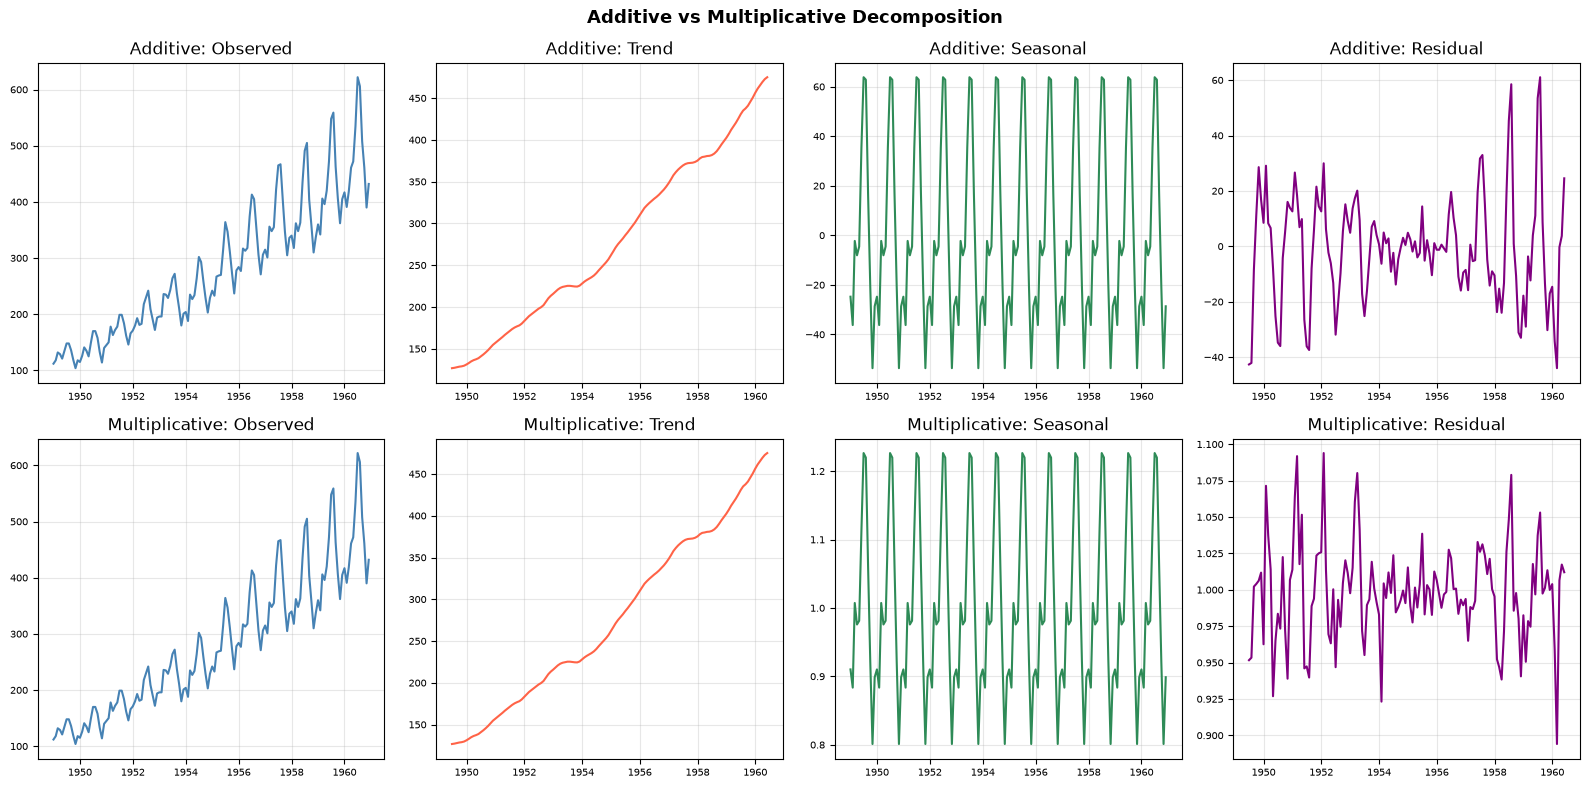


Interpretation:
  • Additive    → seasonal amplitude is CONSTANT over time (Y = Trend + Seasonal + Residual)
  • Multiplicative → seasonal amplitude GROWS with the trend level (Y = Trend × Seasonal × Residual)
  • For Air Passengers the seasonal swings grow over time →
    Multiplicative decomposition is the more appropriate model.



In [19]:
# ── Bonus 2: Additive vs Multiplicative Decomposition Comparison

decomp_add = seasonal_decompose(data['Passengers'], model='additive',      period=12)
decomp_mul = seasonal_decompose(data['Passengers'], model='multiplicative', period=12)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, (decomp, label) in enumerate([(decomp_add, "Additive"), (decomp_mul, "Multiplicative")]):
    axes[i][0].plot(decomp.observed,  color='steelblue'); axes[i][0].set_title(f"{label}: Observed")
    axes[i][1].plot(decomp.trend,     color='tomato');    axes[i][1].set_title(f"{label}: Trend")
    axes[i][2].plot(decomp.seasonal,  color='seagreen');  axes[i][2].set_title(f"{label}: Seasonal")
    axes[i][3].plot(decomp.resid,     color='purple');    axes[i][3].set_title(f"{label}: Residual")
    for ax in axes[i]:
        ax.grid(alpha=0.3)
        ax.tick_params(labelsize=7)

plt.suptitle("Additive vs Multiplicative Decomposition", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("""
Interpretation:
  • Additive    → seasonal amplitude is CONSTANT over time (Y = Trend + Seasonal + Residual)
  • Multiplicative → seasonal amplitude GROWS with the trend level (Y = Trend × Seasonal × Residual)
  • For Air Passengers the seasonal swings grow over time →
    Multiplicative decomposition is the more appropriate model.
""")

### ARIMA Parameter Tuning via AIC

In [22]:
# ARIMA Parameter Tuning via AIC Grid Search

best_aic, best_order = np.inf, None
aic_records = []

for p in range(0, 4):
    for d in [1]:
        for q in range(0, 4):
            try:
                fit = ARIMA(train, order=(p, d, q)).fit()
                aic_records.append({'order': f"({p},{d},{q})", 'AIC': round(fit.aic, 2)})
                if fit.aic < best_aic:
                    best_aic, best_order = fit.aic, (p, d, q)
            except Exception:
                pass

aic_df = pd.DataFrame(aic_records).sort_values('AIC').reset_index(drop=True)
print(aic_df.to_string(index=False))
print(f"\n✔  Best ARIMA order : {best_order}  (AIC = {best_aic:.2f})")

c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\si

  order     AIC
(3,1,3) 1214.91
(2,1,2) 1225.56
(3,1,2) 1242.03
(2,1,1) 1246.26
(3,1,1) 1247.45
(2,1,3) 1249.40
(1,1,2) 1252.97
(1,1,3) 1254.06
(1,1,1) 1257.04
(3,1,0) 1260.17
(0,1,3) 1260.72
(0,1,2) 1261.63
(2,1,0) 1262.53
(0,1,1) 1263.20
(1,1,0) 1266.73
(0,1,0) 1276.26

✔  Best ARIMA order : (3, 1, 3)  (AIC = 1214.91)


### 24-Month Future Forecast

c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


24-Month Forecast (1961–1962) using ARIMA(3, 1, 3):

            Forecast
1961-01-01     471.0
1961-02-01     477.5
1961-03-01     523.6
1961-04-01     546.7
1961-05-01     573.8
1961-06-01     576.2
1961-07-01     568.7
1961-08-01     544.6
1961-09-01     517.6
1961-10-01     491.0
1961-11-01     474.7
1961-12-01     470.7
1962-01-01     480.4
1962-02-01     499.8
1962-03-01     523.5
1962-04-01     544.5
1962-05-01     557.6
1962-06-01     559.5
1962-07-01     550.6
1962-08-01     533.7
1962-09-01     514.0
1962-10-01     496.8
1962-11-01     486.7
1962-12-01     486.0


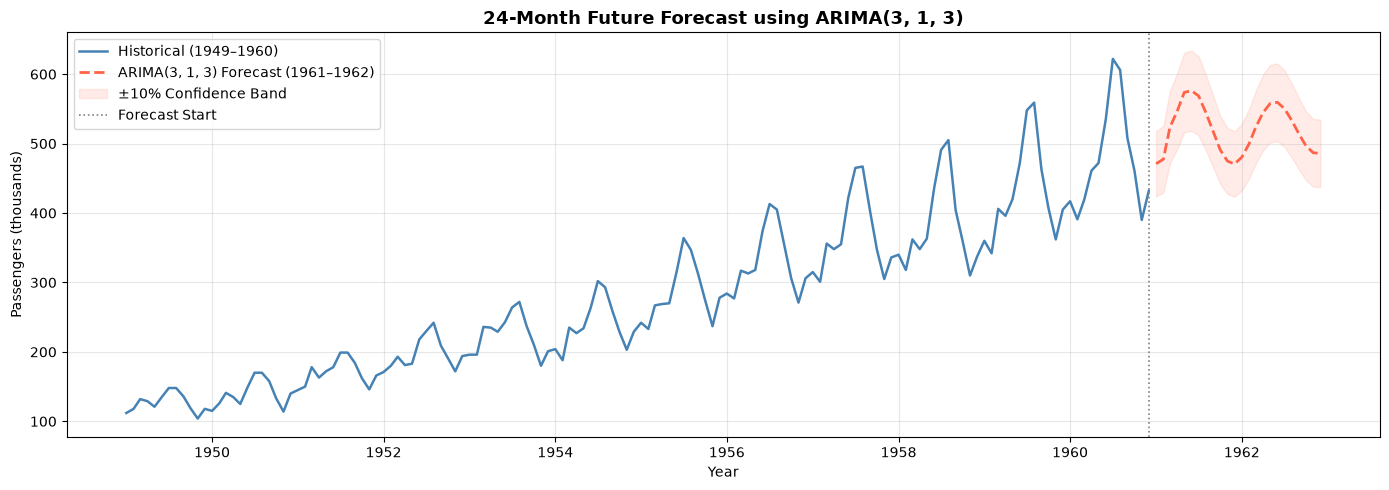

In [21]:
# 24-Month Future Forecast using Best ARIMA Order

best_arima  = ARIMA(data['Passengers'], order=best_order).fit()
fc_24       = best_arima.forecast(steps=24)
idx_24      = pd.date_range(start='1961-01-01', periods=24, freq='MS')
fc_24.index = idx_24

print(f"24-Month Forecast (1961–1962) using ARIMA{best_order}:\n")
print(fc_24.round(1).to_frame(name='Forecast'))

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(data.index, data['Passengers'], color='steelblue', linewidth=1.8, label='Historical (1949–1960)')
ax.plot(idx_24,     fc_24,             color='tomato',    linewidth=2,   linestyle='--',
        label=f'ARIMA{best_order} Forecast (1961–1962)')
ax.fill_between(idx_24, fc_24 * 0.90, fc_24 * 1.10,
                color='tomato', alpha=0.12, label='±10% Confidence Band')
ax.axvline(x=data.index[-1], color='grey', linewidth=1.2, linestyle=':', label='Forecast Start')

ax.set_title(f"24-Month Future Forecast using ARIMA{best_order}", fontsize=13, fontweight='bold')
ax.set_xlabel("Year")
ax.set_ylabel("Passengers (thousands)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()